In [2]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D


In [7]:
image = np.array([
    [1,  2,  3,  4,  5],
    [6,  7,  8,  9, 10],
    [11, 12, 13, 14, 15],
    [16, 17, 18, 19, 20],
    [21, 22, 23, 24, 25]
], dtype=np.float32)

print("Input image:")
print(image)

print("Input shape:", image.shape)

Input image:
[[ 1.  2.  3.  4.  5.]
 [ 6.  7.  8.  9. 10.]
 [11. 12. 13. 14. 15.]
 [16. 17. 18. 19. 20.]
 [21. 22. 23. 24. 25.]]
Input shape: (5, 5)


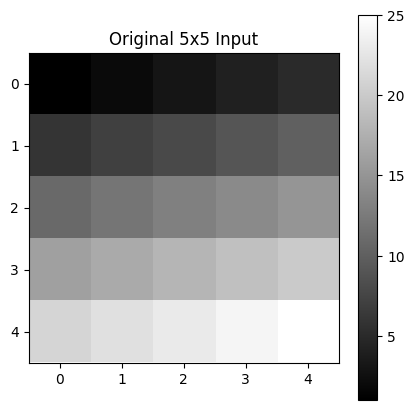

In [8]:
plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("Original 5x5 Input")
plt.colorbar()
plt.show()

In [9]:
input_image = image.reshape(1, 5, 5, 1)

print("CNN input shape:", input_image.shape)

CNN input shape: (1, 5, 5, 1)


# Building Stride 1 model

In [10]:
model_stride1 = Sequential([
    tf.keras.Input(shape=(5, 5, 1)),
    Conv2D(
        filters=1,
        kernel_size=(3, 3),
        strides=1,
        padding="valid",
        use_bias=False
    )
])

print("Stride 1 output shape:", model_stride1.output_shape)

Stride 1 output shape: (None, 3, 3, 1)


# Building Stride 2 model

In [11]:
model_stride2 = Sequential([
    tf.keras.Input(shape=(5, 5, 1)),
    Conv2D(
        filters=1,
        kernel_size=(3, 3),
        strides=2,
        padding="valid",
        use_bias=False
    )
])

print("Stride 2 output shape:", model_stride2.output_shape)

Stride 2 output shape: (None, 2, 2, 1)


In [12]:
kernel = np.ones((3, 3, 1, 1), dtype=np.float32)

model_stride1.layers[0].set_weights([kernel])
model_stride2.layers[0].set_weights([kernel])

print("Filter:")
print(kernel[:, :, 0, 0])

Filter:
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]


In [13]:
output_stride1 = model_stride1.predict(input_image, verbose=0)
output_stride2 = model_stride2.predict(input_image, verbose=0)

feature_map1 = output_stride1[0, :, :, 0]
feature_map2 = output_stride2[0, :, :, 0]

print("Feature map with stride 1:")
print(feature_map1)

print("\nFeature map with stride 2:")
print(feature_map2)

Feature map with stride 1:
[[ 63.  72.  81.]
 [108. 117. 126.]
 [153. 162. 171.]]

Feature map with stride 2:
[[ 63.  81.]
 [153. 171.]]


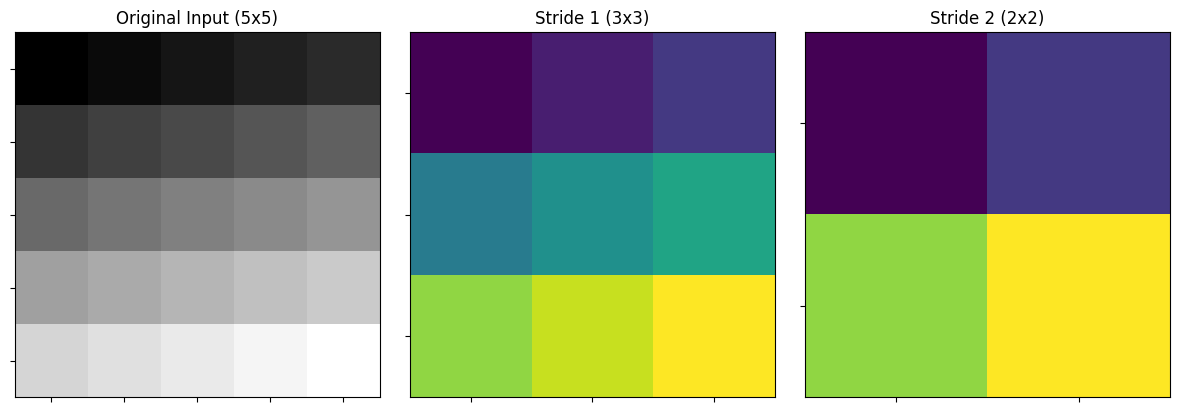

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Input (5x5)")

axes[1].imshow(feature_map1, cmap="viridis")
axes[1].set_title("Stride 1 (3x3)")

axes[2].imshow(feature_map2, cmap="viridis")
axes[2].set_title("Stride 2 (2x2)")

for ax in axes:
    ax.set_xticks(range(ax.images[0].get_array().shape[1]))
    ax.set_yticks(range(ax.images[0].get_array().shape[0]))
    ax.set_xticklabels([])
    ax.set_yticklabels([])

plt.tight_layout()
plt.show()

In [15]:
import math

N = 5
P = 0
K = 3

for stride in [1, 2]:
    output_size = math.floor((N + 2 * P - K) / stride) + 1
    print(f"Stride {stride}: output size = {output_size}x{output_size}")

Stride 1: output size = 3x3
Stride 2: output size = 2x2


In [16]:
print("Comparison of CNN Strides")
print("--------------------------")
print("Input size:", image.shape)
print("Kernel size: 3x3")
print("Stride 1 output:", feature_map1.shape)
print("Stride 2 output:", feature_map2.shape)
print("Stride 1 output values:\n", feature_map1)
print("Stride 2 output values:\n", feature_map2)

Comparison of CNN Strides
--------------------------
Input size: (5, 5)
Kernel size: 3x3
Stride 1 output: (3, 3)
Stride 2 output: (2, 2)
Stride 1 output values:
 [[ 63.  72.  81.]
 [108. 117. 126.]
 [153. 162. 171.]]
Stride 2 output values:
 [[ 63.  81.]
 [153. 171.]]
